# 07:Classifying kidney crops from Phase 1

Phase 1 (notebook 06) gave us a kidney crop for each of the 1,985 ultrasound images, cut out automatically by the DeepLabV3+ segmentation model, together with a fixed 5-fold split. In this notebook we train an EfficientNet-B0 to tell healthy kidneys (label 0) from pathological ones (label 1) using only those crops. In other words: does the classifier still work when nobody draws the kidney by hand?

**What we compare against.** Notebook 05 trained the same kind of model on crops made from the doctors' kidney masks, using the same splits. It reached a pooled out-of-fold ROC-AUC of **0.821** (199 false positives and 186 false negatives at threshold 0.5). This is our reference. The 0.8577 quoted in the sprint plan comes from `DS_28_10.ipynb`, which chose each fold's best epoch by looking at the test fold itself. That makes it too optimistic, so we don't compare against it.

**What this notebook produces** (in `results/phase2_classifier/`):
- five trained models, one per fold, with their decision thresholds;
- `oof_predictions.csv`: for every image, the prediction of the one model that never saw it during training;
- a table of thresholds showing how false positives trade against false negatives.



In [1]:
from pathlib import Path
import random, json, copy
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import scipy.io as sio
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import timm
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, confusion_matrix
from tqdm.auto import tqdm

# Works when started from the repository root or from notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / 'results/eda/folds_master.csv').exists():
    ROOT = ROOT.parent
CROPS = ROOT / 'oof_kidney_crops'
OUT = ROOT / 'results/phase2_classifier'
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Project:', ROOT, '| device:', DEVICE)

Project: /home/pateisreal/projects/kidney_project/Project-data-science | device: cuda


## 1. Load the Phase 1 data and check the splits

We use Phase 1's files as they were delivered:
- `folds_master.csv`: label, cluster (`group_id`) and outer fold for each image. Near-duplicate images share a cluster, and a cluster never appears in more than one fold.
- `oof_kidney_crops/`: the 1,985 automatic crops.

Phase 1 did not include an inner train/validation split, so we use the team's `nested_cv_splits.csv` (also used in notebook 05). Inside each outer fold it divides the remaining images into *train* (to fit the model) and *validation* (to pick the best epoch and the threshold). The test fold is only used at the very end. The checks below make sure the two files agree and that no cluster leaks between train, validation and test.

In [2]:
master = pd.read_csv(ROOT / 'results/eda/folds_master.csv', dtype={'filename': str, 'image_id': str, 'group_id': str})
splits = pd.read_csv(ROOT / 'results/eda/nested_cv_splits.csv', dtype={'filename': str, 'group_id': str})
splits['split'] = splits['split'].replace({'validation': 'val'})

assert len(master) == 1985 and master.filename.is_unique
assert master.groupby('group_id').fold.nunique().max() == 1, 'a cluster appears in two outer folds'
for fold in range(5):
    s = splits[splits.outer_fold == fold].merge(master, on='filename', suffixes=('_split', ''), validate='one_to_one')
    assert len(s) == len(master)
    assert ((s['split'] == 'test') == (s.fold == fold)).all(), 'test part differs from Phase 1 fold'
    assert (s.diagnosis_split == s.diagnosis).all() and (s.group_id_split == s.group_id).all()
    assert s.groupby('group_id')['split'].nunique().max() == 1, 'a cluster is split between train/val/test'
missing = [i for i in master.image_id if not (CROPS / f'{i}.jpg').is_file()]
assert not missing, f'{len(missing)} crops missing, e.g. {missing[:5]}'

print(len(master), 'images,', master.group_id.nunique(), 'clusters; all checks passed')
display(master.groupby(['fold', 'diagnosis']).size().unstack().rename(columns={0: 'healthy', 1: 'pathological'}))

1985 images, 1892 clusters; all checks passed


diagnosis,healthy,pathological
fold,,
0,91,312
1,97,291
2,96,304
3,78,323
4,88,305


## 2. How good are the automatic crops?

Before training, we check that the crops actually contain the kidney and its lesions. Here we use the doctors' kidney masks and lesion boxes, **only to measure the crops**. The classifier never sees them.

- *Kidney coverage*: share of the doctor-drawn kidney that falls inside the crop.
- *Lesion coverage*: share of each lesion box that falls inside the crop.

In [3]:
crop_stats = pd.read_csv(ROOT / 'results/eda/oof_crop_iou_stats.csv', dtype={'image_id': str})
seg_stats = pd.read_csv(ROOT / 'results/eda/deeplabv3p_r50_per_image_metrics.csv', dtype={'image_id': str})
audit = master.merge(crop_stats[['image_id', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1', 'box_iou']], on='image_id', validate='one_to_one')
audit = audit.merge(seg_stats[['image_id', 'dice']], on='image_id', validate='one_to_one')

def label_details(image_id):
    # Reads the view, global pathologies and lesion boxes from the dataset's label file.
    result = {'view': None, 'boxes': []}
    for line in (ROOT / 'bbdd_kidney/labels' / f'{image_id}.txt').read_text().splitlines():
        if ':' not in line: continue
        key, value = (v.strip() for v in line.split(':', 1))
        if key == 'View': result['view'] = int(value)
        elif key.startswith('Bounding box'):
            x, y, w, h, cls = (int(float(v)) for v in value.split()[:5])
            result['boxes'].append((x, y, w, h, cls))
    return result

def overlap_area(a, b):
    return max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))

rows, lesions = [], []
for r in tqdm(audit.itertuples(index=False), total=len(audit), desc='Checking crops'):
    info = label_details(r.image_id)
    kidney = sio.loadmat(ROOT / 'bbdd_kidney/masks' / f'{r.image_id}.mat')['mask'] > 0
    x0, y0, x1, y1 = int(r.crop_x0), int(r.crop_y0), int(r.crop_x1), int(r.crop_y1)
    rows.append(dict(image_id=r.image_id, view=info['view'],
                     kidney_coverage=kidney[y0:y1, x0:x1].sum() / kidney.sum() if kidney.any() else np.nan))
    for x, y, w, h, cls in info['boxes']:
        if w > 0 and h > 0:
            lesions.append(dict(image_id=r.image_id, lesion_class=cls, lesion_coverage=overlap_area((x, y, x + w, y + h), (x0, y0, x1, y1)) / (w * h)))
audit = audit.merge(pd.DataFrame(rows), on='image_id', validate='one_to_one')
lesions = pd.DataFrame(lesions)
audit.to_csv(OUT / 'crop_audit.csv', index=False)
lesions.to_csv(OUT / 'lesion_crop_coverage.csv', index=False)

print(f'Images with less than 95% of the kidney inside the crop: {(audit.kidney_coverage < .95).sum()} of {len(audit)}')
print(f'Lesions with less than 95% of their box inside the crop: {(lesions.lesion_coverage < .95).sum()} of {len(lesions)}')
display(audit[['dice', 'box_iou', 'kidney_coverage']].describe().round(3))

Checking crops:   0%|          | 0/1985 [00:00<?, ?it/s]

Images with less than 95% of the kidney inside the crop: 34 of 1985
Lesions with less than 95% of their box inside the crop: 32 of 2478


,dice,box_iou,kidney_coverage
count,1985.000,1985.000,1985.000
mean,0.923,0.864,0.996
std,0.067,0.104,0.033
min,0.000,0.000,0.000
25%,0.909,0.835,1.000
50%,0.944,0.896,1.000
75%,0.962,0.933,1.000
max,0.984,0.993,1.000


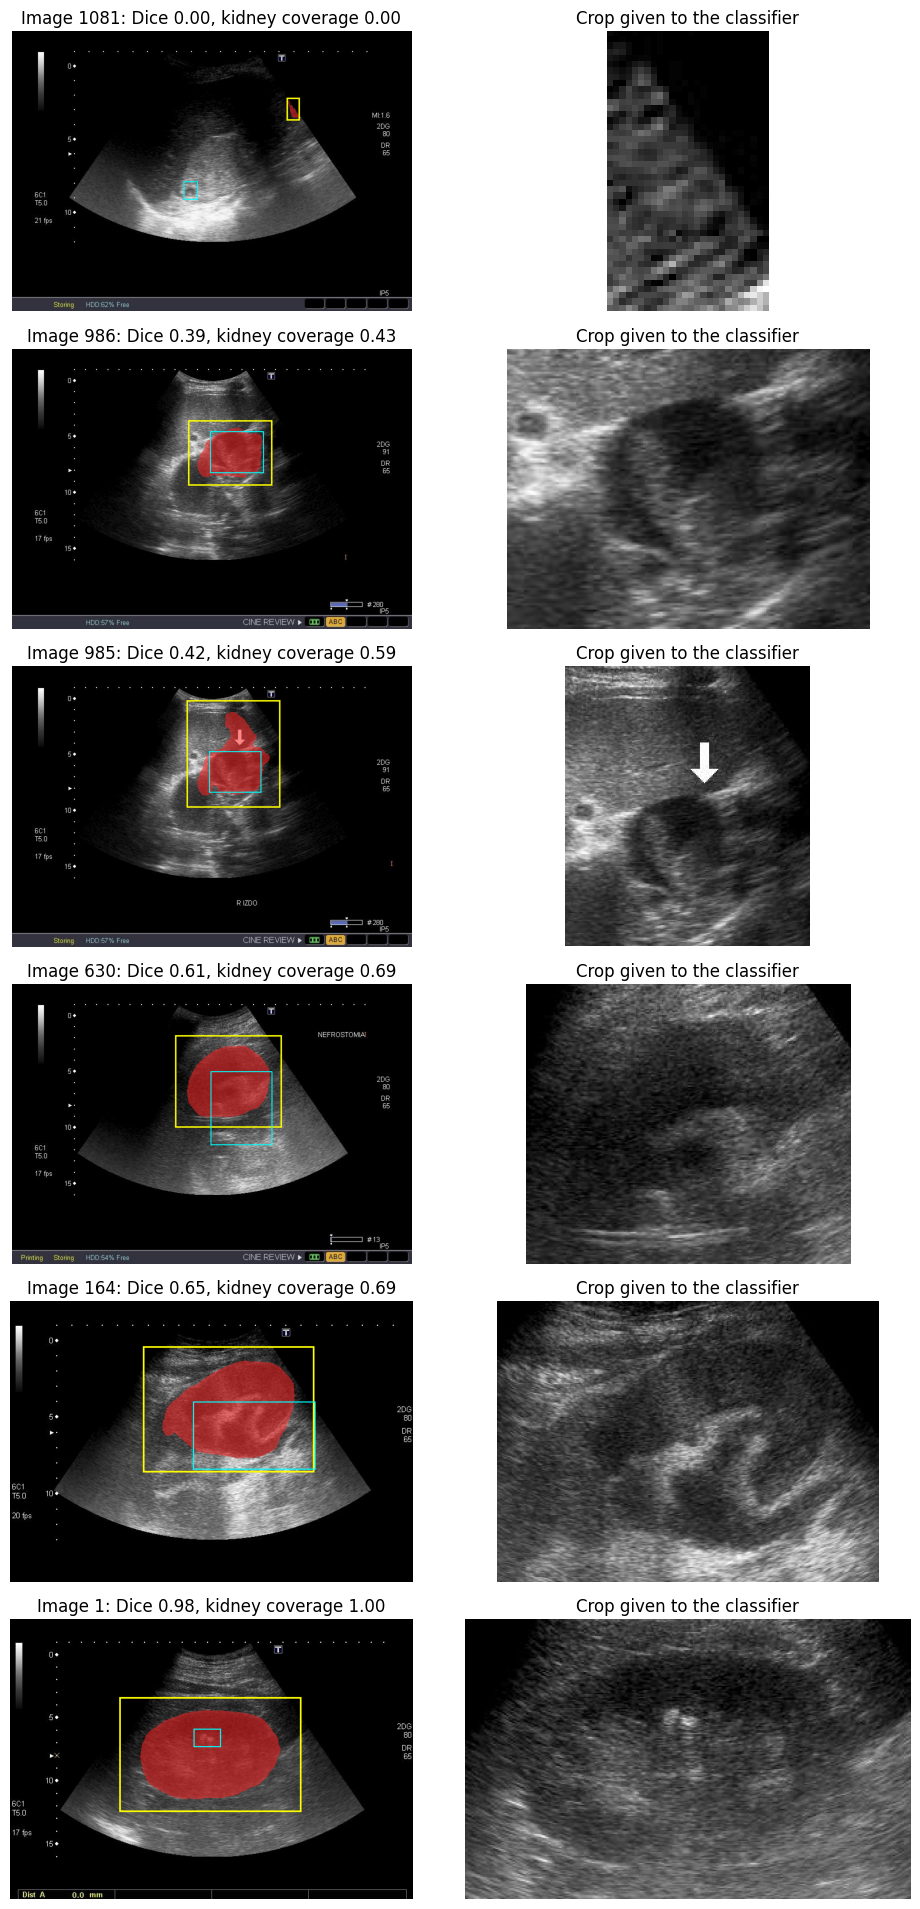

In [4]:
# The five worst crops plus one typical crop. Red = predicted mask, yellow = crop, cyan = lesion boxes.
ids = audit.sort_values('kidney_coverage').image_id.head(5).tolist()
ids.append(audit.iloc[(audit.kidney_coverage - audit.kidney_coverage.median()).abs().argmin()].image_id)
fig, axes = plt.subplots(len(ids), 2, figsize=(10, 3.2 * len(ids)), squeeze=False)
for (ax_full, ax_crop), iid in zip(axes, ids):
    row = audit.set_index('image_id').loc[iid]
    image = np.asarray(Image.open(ROOT / 'bbdd_kidney/images' / f'{iid}.jpg').convert('RGB')).copy()
    mask = np.asarray(Image.open(ROOT / 'oof_binary_masks' / f'{iid}.png').convert('L')) > 0
    image[mask] = (0.45 * image[mask] + 0.55 * np.array([255, 40, 40])).astype('uint8')
    overlay = Image.fromarray(image); draw = ImageDraw.Draw(overlay)
    draw.rectangle((int(row.crop_x0), int(row.crop_y0), int(row.crop_x1), int(row.crop_y1)), outline='yellow', width=3)
    for x, y, w, h, _ in label_details(iid)['boxes']:
        draw.rectangle((x, y, x + w, y + h), outline='cyan', width=2)
    ax_full.imshow(overlay); ax_full.set_title(f'Image {iid}: Dice {row.dice:.2f}, kidney coverage {row.kidney_coverage:.2f}')
    ax_crop.imshow(Image.open(CROPS / f'{iid}.jpg'), cmap='gray'); ax_crop.set_title('Crop given to the classifier')
    ax_full.axis('off'); ax_crop.axis('off')
plt.tight_layout(); plt.show()

Almost every crop contains the whole kidney: only 34 of 1,985 images lose more than 5% of it, and only 32 of 2,478 lesion boxes are partly cut off. In the worst case (image 1081) the segmentation missed the kidney completely (Dice 0); in the next few it found only part of the kidney (Dice 0.39–0.65). They are few enough that they should not change the overall result, but they are good examples for the error audit in Phase 4.

## 3. Training setup

**First attempt.** Our first version of this notebook trained on the same crops but scored clearly lower than notebook 05: ROC-AUC 0.789, and 0.812 with extra contrast/noise augmentation. Its results are kept in `baseline/` and `robust_augmentation/`. Comparing the two notebooks line by line showed that the crops were not the problem. The training recipe was:

1. `timm.create_model(..., num_classes=2)` creates a new output layer with large random weights, so the very first loss was about 3.7 instead of the usual 0.69. The model started far from a sensible answer.
2. There was no per-image brightness normalization, while ultrasound brightness varies a lot between machines and settings.
3. Images were rotated by 90°. A real ultrasound kidney is never shown sideways, so this taught the model something unrealistic.
4. Weak regularization (weight decay 1e-4), 30 epochs and no learning-rate schedule. The model overfit (training loss went down to 0.2).
5. ImageNet mean/std normalization was applied on top, unlike in notebook 05.

**Recipe used now.** We copy notebook 05's settings so that the **only** difference from the reference is where the crops come from:
- a small new output layer (`Dropout(0.3)` + `Linear`);
- each crop's brightness stretched between its 1st and 99th percentile, then resized to 224×224;
- small rotations (±15°), slight contrast changes and light noise during training;
- AdamW (learning rate 1e-4, weight decay 1e-2), learning rate halved every 6 epochs, at most 10 epochs, stopping early if validation ROC-AUC does not improve for 4 epochs.

We train it twice: with **class-weighted** loss, which gives the 450 healthy images more weight than the 1,535 pathological ones, and without, to see whether the weighting helps.

In [5]:
CONFIG = dict(seed=42, image_size=224, batch_size=16, epochs=10, patience=4, lr=1e-4, weight_decay=1e-2)
REFERENCE_NB05 = dict(pooled_auc=0.8209, mean_fold_auc=0.8278, fold_auc=[0.8103, 0.8260, 0.8275, 0.8256, 0.8494],
                      tp=1349, tn=251, fp=199, fn=186)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

class PercentileNormalize:
    # Stretch each image's brightness between its 1st and 99th percentile (same as notebook 05).
    def __call__(self, img):
        a = np.asarray(img.convert('RGB'), dtype=np.float32)
        lo, hi = np.percentile(a, [1, 99])
        a = np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)
        return Image.fromarray((a * 255).astype(np.uint8))

TRAIN_TF = T.Compose([PercentileNormalize(), T.Resize((224, 224)), T.RandomRotation(15), T.ColorJitter(brightness=0, contrast=.15), T.ToTensor(),
                      T.Lambda(lambda x: torch.clamp(x + torch.randn_like(x) * .02, 0, 1) if random.random() < .3 else x)])
EVAL_TF = T.Compose([PercentileNormalize(), T.Resize((224, 224)), T.ToTensor()])

# All crops are small, so we load them into memory once.
CROP_IMAGES = {r.filename: Image.open(CROPS / f'{r.image_id}.jpg').convert('RGB') for r in master.itertuples(index=False)}

class CropDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame, self.transform = frame.reset_index(drop=True), transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        return self.transform(CROP_IMAGES[row.filename]), int(row.diagnosis), row.filename

def make_model(pretrained=True):
    model = timm.create_model('efficientnet_b0', pretrained=pretrained, num_classes=2)
    model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier.in_features, 2))
    return model.to(DEVICE)

@torch.no_grad()
def predict(model, loader):
    model.eval(); rows = []
    for x, y, names in loader:
        probs = torch.softmax(model(x.to(DEVICE)), dim=1)[:, 1].cpu().numpy()
        rows.extend(zip(names, y.numpy().tolist(), probs.tolist()))
    return pd.DataFrame(rows, columns=['filename', 'true_label', 'probability'])

def youden_threshold(y, p):
    # Threshold that maximizes sensitivity + specificity - 1.
    fpr, tpr, thresholds = roc_curve(y, p)
    valid = (thresholds >= 0) & (thresholds <= 1)
    return float(thresholds[np.flatnonzero(valid)[np.argmax((tpr - fpr)[valid])]])

def sensitivity_threshold(y, p, target):
    # Highest threshold that still finds at least `target` of the pathological images.
    fpr, tpr, thresholds = roc_curve(y, p)
    return float(thresholds[np.flatnonzero((tpr >= target) & (thresholds <= 1))[0]])

def metrics(y, p, threshold):
    pred = np.asarray(p) >= np.asarray(threshold)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(auc=float(roc_auc_score(y, p)), f1=float(f1_score(y, pred, zero_division=0)),
                sensitivity=float(tp / (tp + fn)), specificity=float(tn / (tn + fp)), tp=int(tp), tn=int(tn), fp=int(fp), fn=int(fn))

def add_outcomes(df):
    df['outcome'] = np.select([(df.true_label == 1) & (df.predicted_label == 1), (df.true_label == 0) & (df.predicted_label == 0),
                               (df.true_label == 0) & (df.predicted_label == 1)], ['TP', 'TN', 'FP'], default='FN')
    for flag in ['TP', 'TN', 'FP', 'FN']:
        df[flag.lower()] = (df.outcome == flag).astype(int)
    return df

# Quick check: the new output layer should start near the loss of a random guess (about 0.69).
x, y, _ = CropDataset(master.head(1), EVAL_TF)[0]
with torch.no_grad():
    loss = nn.functional.cross_entropy(make_model().eval()(x[None].to(DEVICE)), torch.tensor([y], device=DEVICE))
print(f'{len(CROP_IMAGES)} crops loaded; starting loss {loss.item():.3f}')

1985 crops loaded; starting loss 0.610


In [6]:
def train_cross_validation(experiment, class_weighted):
    output = OUT / experiment / 'imagenet'
    output.mkdir(parents=True, exist_ok=True)
    all_predictions, fold_rows = [], []
    for fold in range(5):
        seed_all(CONFIG['seed'] + fold)
        part = splits[splits.outer_fold == fold][['filename', 'split']].merge(master, on='filename', validate='one_to_one')
        train, val, test = (part[part['split'] == name] for name in ('train', 'val', 'test'))
        loader = lambda frame, tf, shuffle: DataLoader(CropDataset(frame, tf), batch_size=CONFIG['batch_size'], shuffle=shuffle,
                                                       num_workers=0, pin_memory=DEVICE.type == 'cuda')
        train_dl, val_dl, test_dl = loader(train, TRAIN_TF, True), loader(val, EVAL_TF, False), loader(test, EVAL_TF, False)

        model = make_model()
        counts = np.bincount(train.diagnosis.to_numpy(dtype=int), minlength=2)
        class_weights = torch.tensor(len(train) / (2 * counts), dtype=torch.float32, device=DEVICE)
        criterion = nn.CrossEntropyLoss(weight=class_weights if class_weighted else None)
        optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=6, gamma=0.5)

        best_auc, best_state, best_epoch, epochs_without_gain, history = -1.0, None, None, 0, []
        for epoch in range(1, CONFIG['epochs'] + 1):
            model.train(); loss_sum = 0.0
            for x, y, _ in train_dl:
                x, y = x.to(DEVICE), y.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(x), y); loss.backward(); optimizer.step()
                loss_sum += loss.item() * len(y)
            scheduler.step()
            val_pred = predict(model, val_dl)
            auc = roc_auc_score(val_pred.true_label, val_pred.probability)
            history.append(dict(epoch=epoch, train_loss=loss_sum / len(train), val_auc=auc))
            print(f'{experiment} fold {fold} epoch {epoch}: loss {loss_sum / len(train):.4f}, validation AUC {auc:.4f}')
            if auc > best_auc + 1e-6:
                best_auc, best_epoch, epochs_without_gain = auc, epoch, 0
                best_state = copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()})
            else:
                epochs_without_gain += 1
                if epochs_without_gain >= CONFIG['patience']:
                    break

        # Best epoch and threshold come from validation; the test fold is predicted only once, at the end.
        model.load_state_dict(best_state)
        val_pred = predict(model, val_dl)
        threshold = youden_threshold(val_pred.true_label, val_pred.probability)
        test_pred = predict(model, test_dl).merge(master[['filename', 'image_id', 'group_id', 'fold']], on='filename', validate='one_to_one')
        test_pred['threshold'] = threshold
        test_pred['predicted_label'] = (test_pred.probability >= threshold).astype(int)
        all_predictions.append(add_outcomes(test_pred))
        fold_rows.append(dict(fold=fold, threshold=threshold, best_epoch=best_epoch, val_auc=best_auc,
                              **metrics(test_pred.true_label, test_pred.probability, threshold)))
        torch.save(dict(model_state_dict=best_state, architecture='timm efficientnet_b0, classifier=Sequential(Dropout(0.3), Linear(1280, 2))',
                        fold=fold, threshold=threshold, threshold_youden=threshold, threshold_rule='youden on validation',
                        best_epoch=best_epoch, class_weighted=class_weighted, config=CONFIG,
                        preprocessing='Phase 1 crop -> RGB -> percentile 1-99 -> resize 224 -> ToTensor [0,1], no ImageNet mean/std'),
                   output / f'fold_{fold}.pt')
        pd.DataFrame(history).to_csv(output / f'training_history_fold_{fold}.csv', index=False)
        val_pred.to_csv(output / f'inner_validation_predictions_fold_{fold}.csv', index=False)

    predictions = pd.concat(all_predictions, ignore_index=True).sort_values('filename')
    assert len(predictions) == len(master) and set(predictions.filename) == set(master.filename)
    fold_metrics = pd.DataFrame(fold_rows)
    predictions.to_csv(output / 'oof_predictions.csv', index=False)
    fold_metrics.to_csv(output / 'fold_metrics.csv', index=False)
    summary = dict(experiment=experiment, class_weighted=class_weighted, config=CONFIG, reference_nb05=REFERENCE_NB05,
                   pooled_metrics_youden=metrics(predictions.true_label, predictions.probability, predictions.threshold),
                   mean_fold_auc=float(fold_metrics.auc.mean()), std_fold_auc=float(fold_metrics.auc.std()))
    (output / 'summary.json').write_text(json.dumps(summary, indent=2))
    return predictions, fold_metrics

## 4. Train the models

Each run trains five models, one per outer fold. For every image, the saved prediction comes from the model whose test fold contained it, so that model never saw the image during training. Running this cell overwrites `nb06crops_weighted/` and `nb06crops/`.

In [7]:
runs = {'nb06crops_weighted': train_cross_validation('nb06crops_weighted', class_weighted=True),
        'nb06crops': train_cross_validation('nb06crops', class_weighted=False)}

rows = [dict(model='notebook 05, doctor-mask crops (reference)', pooled_auc=REFERENCE_NB05['pooled_auc'],
             mean_fold_auc=REFERENCE_NB05['mean_fold_auc'], **{f'fold {k}': v for k, v in enumerate(REFERENCE_NB05['fold_auc'])})]
for name, label in [('baseline', 'first attempt'), ('robust_augmentation', 'first attempt + contrast/noise'),
                    ('nb06crops', 'this notebook, unweighted'), ('nb06crops_weighted', 'this notebook, class-weighted')]:
    folder = OUT / name / 'imagenet'
    if not (folder / 'oof_predictions.csv').exists():
        continue
    p, f = pd.read_csv(folder / 'oof_predictions.csv'), pd.read_csv(folder / 'fold_metrics.csv')
    rows.append(dict(model=label, pooled_auc=roc_auc_score(p.true_label, p.probability), mean_fold_auc=f.auc.mean(),
                     **{f'fold {k}': v for k, v in zip(f.fold, f.auc)}))
display(pd.DataFrame(rows).set_index('model').round(3))

nb06crops_weighted fold 0 epoch 1: loss 0.6593, validation AUC 0.7113


nb06crops_weighted fold 0 epoch 2: loss 0.5708, validation AUC 0.7467


nb06crops_weighted fold 0 epoch 3: loss 0.5026, validation AUC 0.7986


nb06crops_weighted fold 0 epoch 4: loss 0.4403, validation AUC 0.8064


nb06crops_weighted fold 0 epoch 5: loss 0.3691, validation AUC 0.8106


nb06crops_weighted fold 0 epoch 6: loss 0.3063, validation AUC 0.8125


... (90 outputs left out)

nb06crops fold 4 epoch 8: loss 0.1752, validation AUC 0.8491


nb06crops fold 4 epoch 9: loss 0.1664, validation AUC 0.8542


nb06crops fold 4 epoch 10: loss 0.1158, validation AUC 0.8611


,pooled_auc,mean_fold_auc,fold 0,fold 1,fold 2,fold 3,fold 4
model,,,,,,,
"notebook 05, doctor-mask crops (reference)",0.821,0.828,0.810,0.826,0.828,0.826,0.849
first attempt,0.789,0.790,0.807,0.812,0.757,0.803,0.769
first attempt + contrast/noise,0.812,0.813,0.804,0.814,0.822,0.775,0.852
"this notebook, unweighted",0.831,0.832,0.807,0.829,0.861,0.827,0.836
"this notebook, class-weighted",0.828,0.828,0.795,0.837,0.868,0.801,0.842


**Result.** With the corrected recipe, the automatic crops do **as well as the doctor-mask crops**: pooled ROC-AUC 0.83 against 0.82. So Phase 1's segmentation can replace manual kidney drawing for this task. The two loss settings end up about equal, because weighting the classes mostly shifts the predicted probabilities rather than improving how the images are ranked. We keep the **class-weighted** model for the handoff. It was our planned choice before we saw these numbers, and switching to whichever looks better on the test folds would make the result look better than it really is.

Note that ROC-AUC does not depend on a threshold. How many false positives and false negatives we get depends on the threshold we choose, which is the next step.

## 5. Choosing the decision threshold

A pathological kidney that the model calls healthy (a false negative) is worse than a healthy kidney sent for a follow-up check (a false positive). So the team decided to **favour sensitivity** and accept more false positives.

To keep the evaluation fair, the threshold of each fold is picked on that fold's **validation** images only. It is then applied unchanged to the test fold. The table compares several rules so the trade-off is visible.

In [8]:
def threshold_table(experiment):
    folder = OUT / experiment / 'imagenet'
    oof = pd.read_csv(folder / 'oof_predictions.csv')
    rules = {'fixed 0.5': lambda y, p: 0.5, 'Youden': youden_threshold}
    for target in (0.80, 0.85, 0.875, 0.90, 0.95):
        rules[f'validation sensitivity >= {target:g}'] = lambda y, p, t=target: sensitivity_threshold(y, p, t)
    rows = []
    for name, rule in rules.items():
        thresholds = {}
        for fold in range(5):
            val = pd.read_csv(folder / f'inner_validation_predictions_fold_{fold}.csv')
            thresholds[fold] = rule(val.true_label.to_numpy(), val.probability.to_numpy())
        m = metrics(oof.true_label, oof.probability, oof.fold.map(thresholds))
        rows.append(dict(rule=name, median_threshold=np.median(list(thresholds.values())), **m))
    r = REFERENCE_NB05
    rows.append(dict(rule='notebook 05 reference at 0.5', tp=r['tp'], tn=r['tn'], fp=r['fp'], fn=r['fn'],
                     sensitivity=r['tp'] / (r['tp'] + r['fn']), specificity=r['tn'] / (r['tn'] + r['fp'])))
    table = pd.DataFrame(rows).drop(columns=['auc', 'f1'])
    table.to_csv(folder / 'operating_points.csv', index=False)
    return table.set_index('rule')

for experiment in ['nb06crops_weighted', 'nb06crops']:
    print(experiment)
    display(threshold_table(experiment).round(3))

nb06crops_weighted


,median_threshold,sensitivity,specificity,tp,tn,fp,fn
rule,,,,,,,
fixed 0.5,0.500,0.833,0.669,1278,301,149,257
Youden,0.735,0.749,0.778,1150,350,100,385
validation sensitivity >= 0.8,0.599,0.814,0.718,1249,323,127,286
validation sensitivity >= 0.85,0.392,0.853,0.633,1310,285,165,225
validation sensitivity >= 0.875,0.362,0.871,0.591,1337,266,184,198
validation sensitivity >= 0.9,0.248,0.894,0.527,1373,237,213,162
validation sensitivity >= 0.95,0.125,0.934,0.393,1434,177,273,101
notebook 05 reference at 0.5,NaN,0.879,0.558,1349,251,199,186


nb06crops


,median_threshold,sensitivity,specificity,tp,tn,fp,fn
rule,,,,,,,
fixed 0.5,0.500,0.894,0.540,1372,243,207,163
Youden,0.887,0.728,0.787,1118,354,96,417
validation sensitivity >= 0.8,0.762,0.806,0.716,1237,322,128,298
validation sensitivity >= 0.85,0.627,0.850,0.653,1305,294,156,230
validation sensitivity >= 0.875,0.516,0.867,0.616,1331,277,173,204
validation sensitivity >= 0.9,0.473,0.894,0.558,1372,251,199,163
validation sensitivity >= 0.95,0.268,0.952,0.389,1461,175,275,74
notebook 05 reference at 0.5,NaN,0.879,0.558,1349,251,199,186


### Why we prefer fewer false negatives

The two kinds of mistake do not cost the same:

- **False negative:** a pathological kidney is called healthy. The patient is sent home and the disease may stay untreated until it gets worse. This is the dangerous mistake.
- **False positive:** a healthy kidney is called pathological. A doctor takes a second look or repeats the scan and finds nothing wrong. It costs time and some worry, but it does not harm the patient.

This model is meant as a **first check** whose job is to make sure sick kidneys do not slip through, so we give priority to **fewer false negatives**. There is a limit, though: if the threshold is pushed too low, almost every image is flagged and the tool stops being useful. The rows of the table above that matter most for this decision (class-weighted model):

| Threshold rule | Missed pathological kidneys (FN, of 1,535) | Healthy kidneys flagged (FP, of 450) |
|---|---|---|
| Youden (fewest false positives) | 385 | 100 |
| Validation sensitivity ≥ 0.85 | 225 | 165 |
| **Validation sensitivity ≥ 0.90 (our choice)** | **162** | **213** |
| Validation sensitivity ≥ 0.95 | 101 | 273 |
| Notebook 05 reference (doctor-mask crops, 0.5) | 186 | 199 |

**Our choice: validation sensitivity ≥ 0.90.** On the test folds it finds about 89% of the pathological kidneys (1 in 10 is missed) and sends about half of the healthy kidneys for a second look. Going further to 0.95 would miss only 101 kidneys, but would flag 273 of the 450 healthy ones, and specificity would fall below 40%.

**About the "cut the false positives" goal.** The sprint plan asked us to reduce the 199 false positives of the baseline. The table shows that this is possible: Youden's threshold brings them down to 100 (false-positive rate 44.2% → 22.2%). However, it would miss 385 pathological kidneys instead of 162. Because a missed diagnosis is more harmful than an extra check, we deliberately chose the 90% sensitivity point, even though it gives slightly more false positives than the baseline (213 vs 199). If the team prefers a middle ground, validation sensitivity ≥ 0.85 (165 FP, 225 FN) is a reasonable alternative.

The next cell writes the chosen threshold into the saved models and predictions, so that Phase 3 can use them directly.

In [9]:
HANDOFF_EXPERIMENT, SENSITIVITY_TARGET = 'nb06crops_weighted', 0.90
folder = OUT / HANDOFF_EXPERIMENT / 'imagenet'
rule = f'validation sensitivity >= {SENSITIVITY_TARGET:g}'

thresholds = {}
for fold in range(5):
    val = pd.read_csv(folder / f'inner_validation_predictions_fold_{fold}.csv')
    thresholds[fold] = sensitivity_threshold(val.true_label, val.probability, SENSITIVITY_TARGET)
    checkpoint = torch.load(folder / f'fold_{fold}.pt', map_location='cpu', weights_only=False)
    checkpoint.update(threshold=thresholds[fold], threshold_rule=rule)
    torch.save(checkpoint, folder / f'fold_{fold}.pt')

oof = pd.read_csv(folder / 'oof_predictions.csv')
oof['threshold'] = oof.fold.map(thresholds)
oof['predicted_label'] = (oof.probability >= oof.threshold).astype(int)
add_outcomes(oof).to_csv(folder / 'oof_predictions.csv', index=False)

# For new images, average the five models' probabilities and compare with the median fold threshold.
chosen = dict(rule=rule, fold_thresholds=thresholds, ensemble_threshold=float(np.median(list(thresholds.values()))),
              **metrics(oof.true_label, oof.probability, oof.threshold))
summary = json.loads((folder / 'summary.json').read_text())
summary['chosen_operating_point'] = chosen
(folder / 'summary.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(chosen, indent=2))

{
  "rule": "validation sensitivity >= 0.9",
  "fold_thresholds": {
    "0": 0.2245356142520904,
    "1": 0.2478711456060409,
    "2": 0.1999057233333587,
    "3": 0.2738573849201202,
    "4": 0.5046876668930054
  },
  "ensemble_threshold": 0.2478711456060409,
  "auc": 0.8282656532754253,
  "f1": 0.8798462031400193,
  "sensitivity": 0.8944625407166124,
  "specificity": 0.5266666666666666,
  "tp": 1373,
  "tn": 237,
  "fp": 213,
  "fn": 162
}


## 6. Check the saved models before handing them over

Phase 3 will load these files without this notebook's variables. So we rebuild each model from its file alone, predict 20 of its test images again, and check that we get the same probabilities and thresholds as in `oof_predictions.csv`.

In [10]:
oof = pd.read_csv(folder / 'oof_predictions.csv', dtype={'image_id': str})
for fold in range(5):
    checkpoint = torch.load(folder / f'fold_{fold}.pt', map_location='cpu', weights_only=False)
    model = make_model(pretrained=False)
    model.load_state_dict(checkpoint['model_state_dict']); model.eval()
    fold_rows = oof[oof.fold == fold]
    sample = fold_rows.head(20)
    x = torch.stack([EVAL_TF(Image.open(CROPS / f'{i}.jpg').convert('RGB')) for i in sample.image_id]).to(DEVICE)
    with torch.no_grad():
        p = torch.softmax(model(x), dim=1)[:, 1].cpu().numpy()
    assert (fold_rows.threshold == checkpoint['threshold']).all()
    print(f'fold {fold}: threshold {checkpoint["threshold"]:.4f}, largest probability difference {np.abs(p - sample.probability.to_numpy()).max():.5f}')
print('Outcome counts:', oof[['tp', 'tn', 'fp', 'fn']].sum().to_dict())

fold 0: threshold 0.2245, largest probability difference 0.00000


fold 1: threshold 0.2479, largest probability difference 0.00000


fold 2: threshold 0.1999, largest probability difference 0.00000


fold 3: threshold 0.2739, largest probability difference 0.00000


fold 4: threshold 0.5047, largest probability difference 0.00000
Outcome counts: {'tp': 1373, 'tn': 237, 'fp': 213, 'fn': 162}


## Summary

- **The automatic crops from Phase 1 work as well as doctor-drawn crops** (pooled ROC-AUC 0.83 vs 0.82). The earlier, weaker results came from the training recipe, not from the crops.
- **Model handed to Phase 3:** `results/phase2_classifier/nb06crops_weighted/imagenet/`, which contains five fold models (`fold_k.pt`, with their thresholds) and `oof_predictions.csv`.
- **Operating point:** validation sensitivity ≥ 0.90, about 89% sensitivity and 53% specificity on the test folds (162 missed pathological kidneys, 213 false positives). We favoured fewer missed diagnoses over fewer false positives; Youden's threshold would cut false positives to 100 but miss 385 pathological kidneys (see section 5). Use threshold 0.2479 when averaging all five models.
- **How Phase 3 should use it:** feed the Phase 1 crop with the same preprocessing as `EVAL_TF` (no ImageNet mean/std), build the network with `make_model(pretrained=False)`, and explain each image with the model of its own fold. Details are in `results/phase2_classifier/PHASE2_HANDOFF.md`.

**Limitations**
- All numbers are internal cross-validation results on one dataset. KidneyUS has no pathology labels, so there is no external test of the classifier.
- The segmentation model that cropped a *training* image might have seen some of the classifier's test images during its own training. Each crop is still out-of-fold for its own image, but the full pipeline has not been checked for this.
- The planned ImageNet vs RadImageNet comparison was not done. RadImageNet only provides pretrained weights for ResNet50, DenseNet121, InceptionV3 and InceptionResNetV2, not for EfficientNet-B0. Creating them ourselves would mean training on its 1.35 million images for more than a week, so the team decided to keep the ImageNet-pretrained EfficientNet-B0.